# 02 - Exploratory Data Analysis (EDA)

**Goal:** understand overall booking behavior before diving into business questions.

**Questions to answer:**
- How many bookings are City Hotel vs Resort Hotel?
- Does booking volume follow a seasonal pattern (which months/quarters are busiest)?
- What does the lead-time and ADR distribution look like?
- Which numeric features correlate with each other (and with cancellation)?

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np

from src.config import CLEAN_DATA_PATH
from src.analysis import hotel_type_distribution, monthly_booking_trend, adr_by_hotel
from src.visualization import (
    plot_hotel_type_distribution,
    plot_monthly_booking_trend,
    plot_lead_time_distribution,
    plot_adr_by_hotel,
    plot_correlation_heatmap,
)

df = pd.read_csv(CLEAN_DATA_PATH)
df.shape

(87139, 31)

## Hotel type distribution

hotel
City Hotel      53261
Resort Hotel    33878
Name: count, dtype: int64

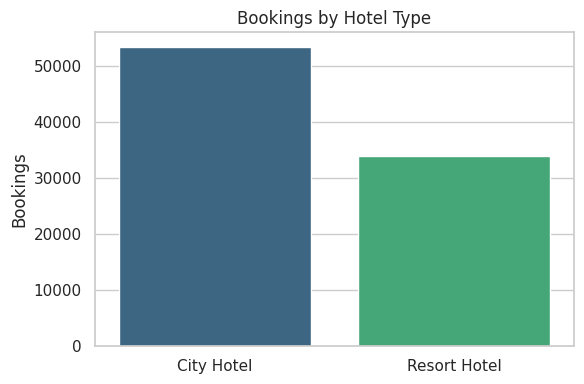

In [2]:
hotel_counts = hotel_type_distribution(df)
plot_hotel_type_distribution(hotel_counts)
hotel_counts

## Booking trend over time (monthly / seasonal)

arrival_date_month
January       4685
February      6083
March         7487
April         7899
May           8341
June          7756
July         10026
August       11186
September     6681
October       6921
November      4973
December      5101
Name: count, dtype: int64

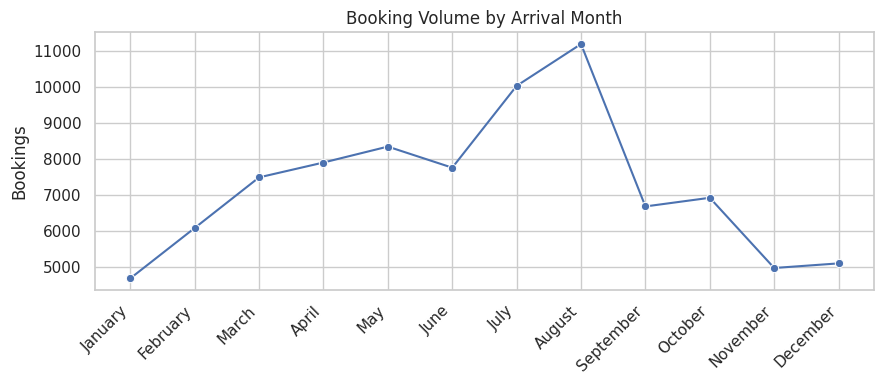

In [3]:
monthly_counts = monthly_booking_trend(df)
plot_monthly_booking_trend(monthly_counts)
monthly_counts

## Lead time distribution

<Axes: title={'center': 'Lead Time Distribution'}, xlabel='lead_time', ylabel='Count'>

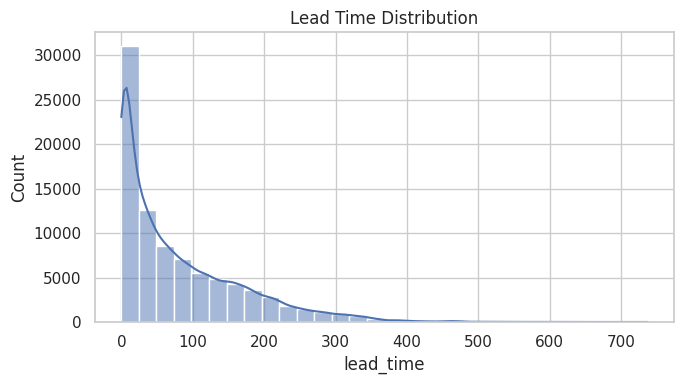

In [4]:
plot_lead_time_distribution(df)

## ADR (price) by hotel type

<Axes: title={'center': 'ADR by Hotel Type'}, xlabel='hotel', ylabel='adr'>

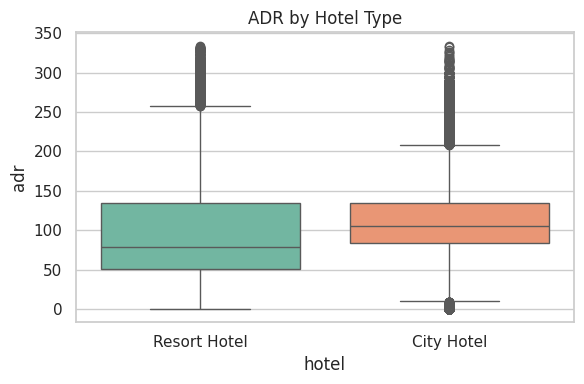

In [5]:
plot_adr_by_hotel(adr_by_hotel(df))

## Correlation heatmap

<Axes: title={'center': 'Numeric Feature Correlation'}>

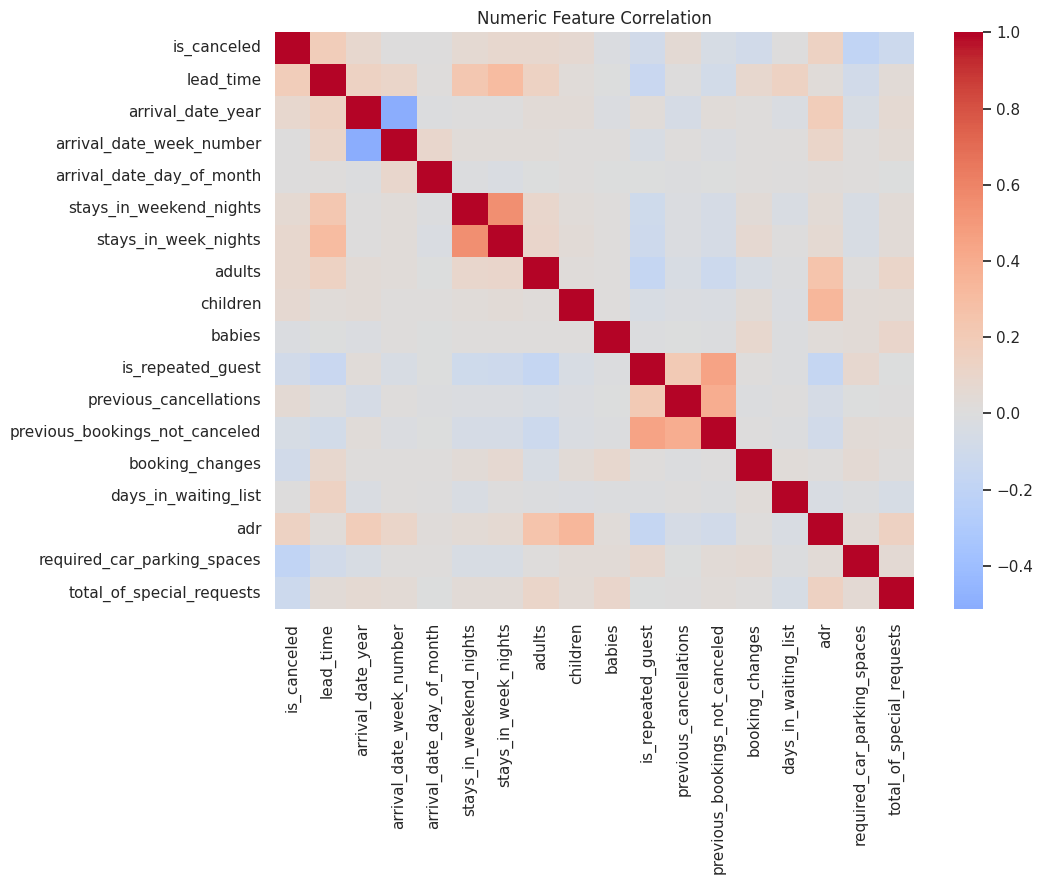

In [6]:
plot_correlation_heatmap(df)

## Takeaways

In [7]:
peak_month = monthly_counts.idxmax()
low_month = monthly_counts.idxmin()
city_share = hotel_counts['City Hotel'] / hotel_counts.sum()
print(f"- City Hotel accounts for {city_share:.1%} of all bookings, Resort Hotel the rest.")
print(f"- Booking volume peaks in {peak_month} and is lowest in {low_month} — demand is clearly seasonal.")
print(f"- Lead time is right-skewed: most guests book close to arrival, with a long tail of far-ahead bookers.")

- City Hotel accounts for 61.1% of all bookings, Resort Hotel the rest.
- Booking volume peaks in August and is lowest in January — demand is clearly seasonal.
- Lead time is right-skewed: most guests book close to arrival, with a long tail of far-ahead bookers.
